# This notebook covers the following feature engineering operations:

- Time-Based Feature Engineering
- Rolling Window Features
- Lagged Features
- Feature Interaction and Domain-Specific Features

In [56]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path
from sklearn.model_selection import train_test_split
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import MinMaxScaler

### 1. Load data set

In [18]:
outlier_handled_df = "../data/processed/cleaned_outlier_data.csv"
df = pd.read_csv(outlier_handled_df)

df_cp = df.copy()

In [19]:
df_cp.head()

,date,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,...,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2,Appliances
0,2016-01-11 17:00:00,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,...,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433,60
1,2016-01-11 17:10:00,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,...,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195,60
2,2016-01-11 17:20:00,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,...,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668,50
3,2016-01-11 17:30:00,30,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,...,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389,50
4,2016-01-11 17:40:00,30,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,...,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097,60


### 2. Extract basic time features

In [20]:
# Convert 'date' column to datetime and set it as the index
df_cp['date'] = pd.to_datetime(df_cp['date'])
df_cp = df_cp.set_index('date')

# Basic time features
df_cp['hour'] = df_cp.index.hour
df_cp['day_of_week'] = df_cp.index.dayofweek
df_cp['month'] = df_cp.index.month
df_cp['is_weekend'] = (df_cp['day_of_week'] >= 5).astype(int)

# Cyclical Encoding (very important)
df_cp['hour_sin'] = np.sin(2 * np.pi * df_cp['hour'] / 24)
df_cp['hour_cos'] = np.cos(2 * np.pi * df_cp['hour'] / 24)
df_cp['dow_sin']  = np.sin(2 * np.pi * df_cp['day_of_week'] / 7)
df_cp['dow_cos']  = np.cos(2 * np.pi * df_cp['day_of_week'] / 7)

C:\Users\naduk\AppData\Local\Temp\ipykernel_17828\4113860485.py:7: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df_cp['day_of_week'] = df_cp.index.dayofweek


In [21]:
df_cp

,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,...,rv2,Appliances,hour,day_of_week,month,is_weekend,hour_sin,hour_cos,dow_sin,dow_cos
date,,,,,,,,,,,,,,,,,,,,,
2016-01-11 17:00:00,30,19.890000,47.596667,19.200000,44.790000,19.790000,44.730000,19.000000,45.566667,17.166667,...,13.275433,60,17,0,1,0,-0.965926,-2.588190e-01,0.000000,1.000000
2016-01-11 17:10:00,30,19.890000,46.693333,19.200000,44.722500,19.790000,44.790000,19.000000,45.992500,17.166667,...,18.606195,60,17,0,1,0,-0.965926,-2.588190e-01,0.000000,1.000000
2016-01-11 17:20:00,30,19.890000,46.300000,19.200000,44.626667,19.790000,44.933333,18.926667,45.890000,17.166667,...,28.642668,50,17,0,1,0,-0.965926,-2.588190e-01,0.000000,1.000000
2016-01-11 17:30:00,30,19.890000,46.066667,19.200000,44.590000,19.790000,45.000000,18.890000,45.723333,17.166667,...,45.410389,50,17,0,1,0,-0.965926,-2.588190e-01,0.000000,1.000000
2016-01-11 17:40:00,30,19.890000,46.333333,19.200000,44.530000,19.790000,45.000000,18.890000,45.530000,17.200000,...,10.084097,60,17,0,1,0,-0.965926,-2.588190e-01,0.000000,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2016-05-27 17:20:00,0,25.566667,46.560000,25.890000,42.025714,27.200000,41.163333,24.700000,45.590000,23.200000,...,43.096812,100,17,4,5,0,-0.965926,-2.588190e-01,-0.433884,-0.900969
2016-05-27 17:30:00,0,25.500000,46.500000,25.754000,42.080000,27.133333,41.223333,24.700000,45.590000,23.230000,...,49.282940,90,17,4,5,0,-0.965926,-2.588190e-01,-0.433884,-0.900969
2016-05-27 17:40:00,10,25.500000,46.596667,25.628571,42.768571,27.050000,41.690000,24.700000,45.730000,23.230000,...,29.199117,270,17,4,5,0,-0.965926,-2.588190e-01,-0.433884,-0.900969


### 3. Lagged Features + ACF/PACF

#### 3.1 ACF & PACF plots (to decide which lags are useful)

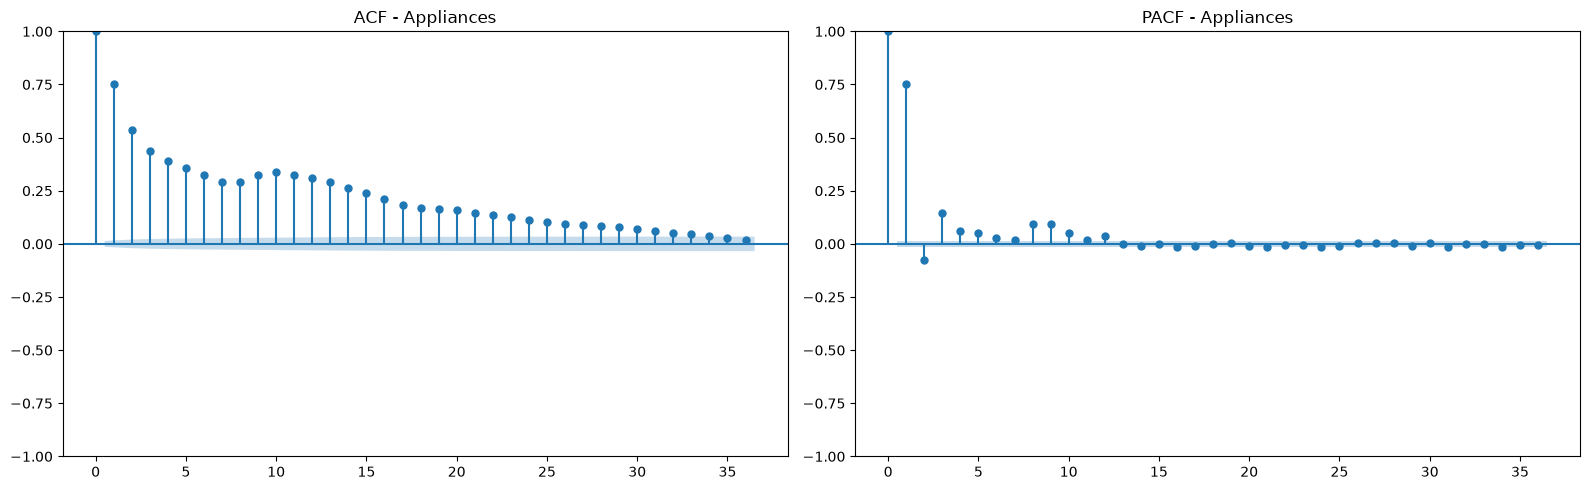

In [22]:
y = df_cp['Appliances']

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
plot_acf(y, lags=36, ax=axes[0], title="ACF - Appliances")
plot_pacf(y, lags=36, ax=axes[1], title="PACF - Appliances")
plt.tight_layout()
plt.show()

#### 3.2 Create Lag Features

In [23]:
lags = [1, 2, 3, 6, 12, 18, 36]

for lag in lags:
    df_cp[f'lag_{lag}'] = df_cp['Appliances'].shift(lag)

print("Lag features created successfully!")

Lag features created successfully!


In [24]:
df_cp.head()

,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,...,hour_cos,dow_sin,dow_cos,lag_1,lag_2,lag_3,lag_6,lag_12,lag_18,lag_36
date,,,,,,,,,,,,,,,,,,,,,
2016-01-11 17:00:00,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,17.166667,...,-0.258819,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-01-11 17:10:00,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,17.166667,...,-0.258819,0.0,1.0,60.0,NaN,NaN,NaN,NaN,NaN,NaN
2016-01-11 17:20:00,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,17.166667,...,-0.258819,0.0,1.0,60.0,60.0,NaN,NaN,NaN,NaN,NaN
2016-01-11 17:30:00,30,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,17.166667,...,-0.258819,0.0,1.0,50.0,60.0,60.0,NaN,NaN,NaN,NaN
2016-01-11 17:40:00,30,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,17.200000,...,-0.258819,0.0,1.0,50.0,50.0,60.0,NaN,NaN,NaN,NaN


In [25]:
df_cp.isnull().sum()

lights          0
T1              0
RH_1            0
T2              0
RH_2            0
T3              0
RH_3            0
T4              0
RH_4            0
T5              0
RH_5            0
T6              0
RH_6            0
T7              0
RH_7            0
T8              0
RH_8            0
T9              0
RH_9            0
T_out           0
Press_mm_hg     0
RH_out          0
Windspeed       0
Visibility      0
Tdewpoint       0
rv1             0
rv2             0
Appliances      0
hour            0
day_of_week     0
month           0
is_weekend      0
hour_sin        0
hour_cos        0
dow_sin         0
dow_cos         0
lag_1           1
lag_2           2
lag_3           3
lag_6           6
lag_12         12
lag_18         18
lag_36         36
dtype: int64

### 4. Rolling Window Features

In [26]:
for window, name in [(6, '1h'), (12, '2h'), (18, '3h')]:
    rolling = df_cp['Appliances'].shift(1).rolling(window=window)
    df_cp[f'roll_mean_{name}'] = rolling.mean()
    df_cp[f'roll_std_{name}'] = rolling.std()

In [27]:
df_cp.head()

,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,...,lag_6,lag_12,lag_18,lag_36,roll_mean_1h,roll_std_1h,roll_mean_2h,roll_std_2h,roll_mean_3h,roll_std_3h
date,,,,,,,,,,,,,,,,,,,,,
2016-01-11 17:00:00,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,17.166667,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-01-11 17:10:00,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,17.166667,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-01-11 17:20:00,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,17.166667,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-01-11 17:30:00,30,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,17.166667,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-01-11 17:40:00,30,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,17.200000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 5. Interaction & Domain Features

In [28]:
# Average indoor temperature & humidity
temp_cols = ['T1','T2','T3','T4','T5','T7','T8','T9']
rh_cols   = ['RH_1','RH_2','RH_3','RH_4','RH_5','RH_7','RH_8','RH_9']

df_cp['temp_in_mean'] = df_cp[temp_cols].mean(axis=1)
df_cp['rh_in_mean']   = df_cp[rh_cols].mean(axis=1)

# Interaction Features
df_cp['temp_x_humidity'] = df_cp['temp_in_mean'] * df_cp['rh_in_mean']
df_cp['in_out_temp_diff'] = df_cp['temp_in_mean'] - df_cp['T_out']

# Domain Feature
df_cp['lights_on'] = (df_cp['lights'] > 0).astype(int)

In [30]:
df_cp.isnull().sum()

lights               0
T1                   0
RH_1                 0
T2                   0
RH_2                 0
T3                   0
RH_3                 0
T4                   0
RH_4                 0
T5                   0
RH_5                 0
T6                   0
RH_6                 0
T7                   0
RH_7                 0
T8                   0
RH_8                 0
T9                   0
RH_9                 0
T_out                0
Press_mm_hg          0
RH_out               0
Windspeed            0
Visibility           0
Tdewpoint            0
rv1                  0
rv2                  0
Appliances           0
hour                 0
day_of_week          0
month                0
is_weekend           0
hour_sin             0
hour_cos             0
dow_sin              0
dow_cos              0
lag_1                1
lag_2                2
lag_3                3
lag_6                6
lag_12              12
lag_18              18
lag_36              36
roll_mean_1

### 6. Handle null values

In [32]:
# Remove null values
print("Shape before dropping NaNs:", df_cp.shape)

# Drop rows with any NaN
df_cp = df_cp.dropna()

print("Shape after dropping NaNs:", df_cp.shape)
print("Remaining NaNs:", df_cp.isnull().sum().sum())

Shape before dropping NaNs: (19735, 54)
Shape after dropping NaNs: (19699, 54)
Remaining NaNs: 0


In [34]:
df_cp.head()

,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,...,roll_std_1h,roll_mean_2h,roll_std_2h,roll_mean_3h,roll_std_3h,temp_in_mean,rh_in_mean,temp_x_humidity,in_out_temp_diff,lights_on
date,,,,,,,,,,,,,,,,,,,,,
2016-01-11 23:00:00,20,21.6,44.200000,21.000000,43.590,20.4175,45.545000,21.166667,46.526667,19.29,...,154.099535,185.000000,134.468651,165.000000,113.823909,19.677604,45.972708,904.632757,13.777604,1
2016-01-11 23:10:00,20,21.6,44.200000,21.000000,43.590,20.3900,45.663333,21.033333,46.400000,19.29,...,165.217029,180.833333,137.738773,163.888889,114.795926,19.661667,46.112500,906.648604,13.861667,1
2016-01-11 23:20:00,10,21.6,44.200000,21.000000,43.700,20.2900,45.730000,20.963333,46.433333,19.29,...,165.217029,176.666667,140.798588,159.444444,117.296619,19.640417,46.197917,907.346332,13.940417,1
2016-01-11 23:30:00,20,21.5,44.230000,20.926667,43.760,20.2900,45.790000,20.865000,46.567500,19.29,...,141.232669,172.500000,143.977587,155.555556,119.814672,19.606458,46.313437,908.042483,14.006458,1
2016-01-11 23:40:00,20,21.5,44.363333,20.890000,43.845,20.2900,45.790000,20.730000,46.590000,19.29,...,73.756356,170.000000,145.602198,148.888889,121.116807,19.585000,46.391042,908.568551,14.085000,1


### 6. Feature selection 

In [ ]:
"""
Split dataset into train and test
"""

# Chronological split (80% Train, 20% Test)
split_index = int(len(df_cp) * 0.8)

train = df_cp.iloc[:split_index]
test  = df_cp.iloc[split_index:]

print("Train period:", train.index.min(), "→", train.index.max())
print("Test period :", test.index.min(), "→", test.index.max())
print("Train shape :", train.shape)
print("Test shape  :", test.shape)

Train period: 2016-01-11 23:00:00 → 2016-04-30 09:20:00
Test period : 2016-04-30 09:30:00 → 2016-05-27 18:00:00
Train shape : (15759, 54)
Test shape  : (3940, 54)


In [46]:
""" Drop unnessasary columns """

TARGET = 'Appliances'

# Columns to drop raw time columns already have sin/cos
drop_cols = [TARGET, 'hour', 'day_of_week', 'month']

features = [col for col in df_cp.columns if col not in drop_cols]

X_train = train[features]
y_train = train[TARGET]

X_test = test[features]
y_test = test[TARGET]

print("Number of features:", len(features))
print("X_train shape ", X_train.shape)
print("y_train shape ", y_train.shape)
print("X_test shape ", X_test.shape)
print("y_test shape ", y_test.shape)


Number of features: 50
X_train shape  (15759, 50)
y_train shape  (15759,)
X_test shape  (3940, 50)
y_test shape  (3940,)


In [47]:
""" Feature selection using random forest"""

# Train Random Forest only on training data
rf = RandomForestRegressor(
                           n_estimators=100,
                           max_depth=12,
                           random_state=42,
                           n_jobs=-1
                          )

rf.fit(X_train, y_train)

# Get feature importance
importance = pd.Series(rf.feature_importances_, index=features)
importance = importance.sort_values(ascending=False)

# Display top features
print("Top 15 Important Features:")
print(importance.head(15))

Top 15 Important Features:
lag_1           0.664553
lag_2           0.034490
roll_mean_3h    0.013769
roll_std_2h     0.011832
hour_sin        0.010239
lag_12          0.010057
lag_3           0.009965
roll_std_1h     0.009828
roll_std_3h     0.009159
Press_mm_hg     0.009136
roll_mean_1h    0.008915
roll_mean_2h    0.008862
hour_cos        0.008490
T4              0.008450
RH_2            0.007335
dtype: float64


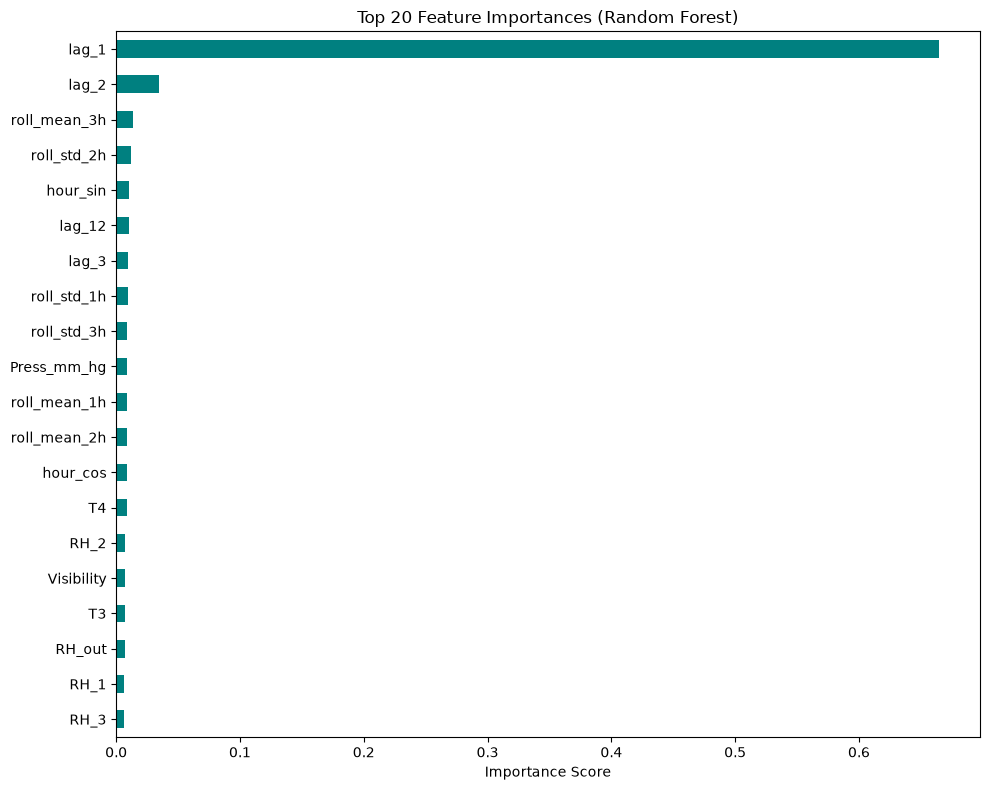

In [50]:
plt.figure(figsize=(10, 8))
importance.head(20).sort_values().plot(kind='barh', color='teal')
plt.title("Top 20 Feature Importances (Random Forest)")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()

### 7. Remove Highly Correlated Features

In [51]:
# Calculate correlation on training set
corr_matrix = X_train.corr().abs()

# Upper triangle of correlation matrix
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Find features with correlation > 0.95
redundant_features = [column for column in upper.columns if any(upper[column] > 0.95)]

print("Highly correlated features to remove:")
print(redundant_features)

Highly correlated features to remove:
['T_out', 'rv2', 'in_out_temp_diff']


### 8. Final Selected Features

In [53]:
# Keep top important features and remove redundant ones
selected_features = [f for f in importance.index[:25] if f not in redundant_features]

print(f"\nFinal selected features ({len(selected_features)}):")
print(selected_features)

# Update X_train and X_test
X_train = X_train[selected_features]
X_test = X_test[selected_features]


Final selected features (24):
['lag_1', 'lag_2', 'roll_mean_3h', 'roll_std_2h', 'hour_sin', 'lag_12', 'lag_3', 'roll_std_1h', 'roll_std_3h', 'Press_mm_hg', 'roll_mean_1h', 'roll_mean_2h', 'hour_cos', 'T4', 'RH_2', 'Visibility', 'T3', 'RH_out', 'RH_1', 'RH_3', 'Windspeed', 'T6', 'RH_6', 'RH_5']


In [54]:
print("X_train shape ", X_train.shape)
print("y_train shape ", y_train.shape)
print("X_test shape ", X_test.shape)
print("y_test shape ", y_test.shape)

X_train shape  (15759, 24)
y_train shape  (15759,)
X_test shape  (3940, 24)
y_test shape  (3940,)


### 9. Scaling  and Normalization

In [58]:
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled  = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1))
y_test_scaled  = scaler_y.transform(y_test.values.reshape(-1, 1))

print("Scaling completed!")
print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape :", X_test_scaled.shape)

Scaling completed!
X_train_scaled shape: (15759, 24)
X_test_scaled shape : (3940, 24)


### 10. Saved data set 


In [63]:
os.makedirs("../data/processed", exist_ok=True)
os.makedirs("../artifacts/scalers", exist_ok=True)

# Save scaled arrays
np.save("../data/processed/X_train_scaled.npy", X_train_scaled)
np.save("../data/processed/X_test_scaled.npy", X_test_scaled)
np.save("../data/processed/y_train_scaled.npy", y_train_scaled)
np.save("../data/processed/y_test_scaled.npy", y_test_scaled)

# # Save original y (for evaluation)
np.save("../data/processed/y_train.npy", y_train.values)
np.save("../data/processed/y_test.npy", y_test.values)

# # Save scalers
joblib.dump(scaler_X, "../artifacts/scalers/scaler_X.pkl")
joblib.dump(scaler_y, "../artifacts/scalers/scaler_y.pkl")

# # Save selected feature names
joblib.dump(selected_features, "../artifacts/scalers/selected_features.pkl")

print("All files saved successfully!")

All files saved successfully!
